In [264]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [265]:
df = pd.read_csv("Experience-Salary.csv")
df.head()

,exp(in months),salary(in thousands)
0,18.290293,16.521825
1,17.023407,11.666234
2,26.343613,23.167255
3,19.105834,20.877145
4,27.742516,23.166236


In [266]:
df.shape

(1000, 2)

In [267]:
x = df[['exp(in months)']]
x.shape

(1000, 1)

In [268]:
y = df[['salary(in thousands)']]
y.shape

(1000, 1)

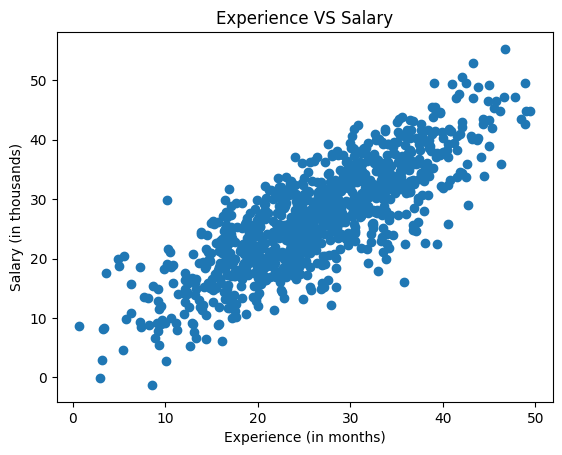

In [269]:
plt.scatter(df["exp(in months)"], df["salary(in thousands)"])
plt.title("Experience VS Salary")
plt.xlabel("Experience (in months)")
plt.ylabel("Salary (in thousands)")
plt.show()

In [270]:
x = df.iloc[:,0:1]
x

,exp(in months)
0,18.290293
1,17.023407
2,26.343613
3,19.105834
4,27.742516
...,...
995,22.161741
996,32.266497
997,17.039030
998,25.222124


In [271]:
y = df.iloc[:,-1]
y

,salary(in thousands)
0,16.521825
1,11.666234
2,23.167255
3,20.877145
4,23.166236
...,...
995,24.666502
996,24.160270
997,19.903797
998,21.974413


In [272]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=2)

In [273]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train, y_train)

LinearRegression()

In [274]:
lr.predict(X_train.iloc[0].values.reshape(1,1))

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([31.56933712])

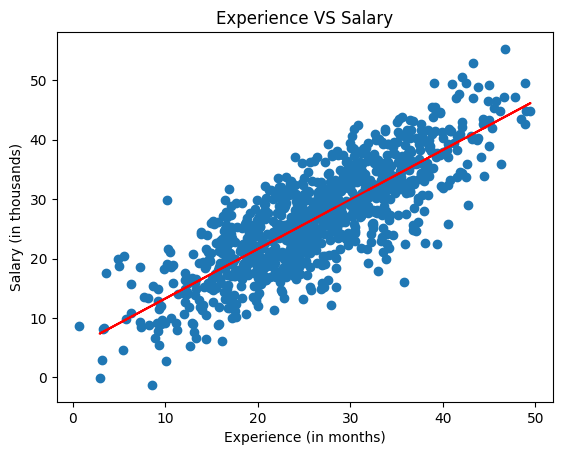

In [275]:
plt.scatter(df["exp(in months)"],df["salary(in thousands)"])
plt.plot(X_train, lr.predict(X_train),color = "red")
plt.xlabel("Experience (in months)")
plt.ylabel("Salary (in thousands)")
plt.title("Experience VS Salary")
plt.show()

In [276]:
m = lr.coef_
b = lr.intercept_

In [277]:
lr.coef_

array([0.83313436])

In [278]:
lr.intercept_

np.float64(4.953899514865196)

In [279]:
#y = m*x + b
m*8.45 + b


array([11.99388485])

In [280]:
m*9.55 + b

array([12.91033265])

# USE CLASS METHOD




In [281]:
class MeraLR:

  def __init__(self):
    self.m = None
    self.b = None

  def fit(self, X_train, y_train):

    num = 0
    den = 0

    for i in range(X_train.shape[0]):
      num = num + (X_train[i] - X_train.mean()) * (y_train[i] - y_train.mean())
      den = den + ((X_train[i] - X_train.mean())**2)

    self.m = num / den
    self.b = y_train.mean() - (self.m * X_train.mean())

    print("Slope (m):", self.m)
    print("Intercept (b):", self.b)

  def predict(self, X_test):
    print(X_test)

    return self.m * X_test + self.b

In [282]:
x = df.iloc[:,0]
x

,exp(in months)
0,18.290293
1,17.023407
2,26.343613
3,19.105834
4,27.742516
...,...
995,22.161741
996,32.266497
997,17.039030
998,25.222124


In [283]:
y = df.iloc[:,-1]
y

,salary(in thousands)
0,16.521825
1,11.666234
2,23.167255
3,20.877145
4,23.166236
...,...
995,24.666502
996,24.160270
997,19.903797
998,21.974413


In [284]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=2)

In [285]:
X_train.shape

(800,)

In [286]:
X_train.mean()

np.float64(26.33500567681572)

In [287]:
lr = MeraLR()
# Convert to numpy arrays to avoid KeyError during pandas label-based indexing
lr.fit(X_train.values, y_train.values)

Slope (m): 0.8331343595526576
Intercept (b): 4.953899514865185


In [288]:
lr.predict(X_test.iloc[0])

29.78202485733172


np.float64(29.766327720559577)

In [289]:
from sklearn.metrics import mean_absolute_error, mean_squared_log_error, r2_score

In [290]:
print("MAE", mean_absolute_error(y_test, lr.predict(X_test)))


37     29.782025
726    20.432469
846    41.839941
295    38.049936
924    23.254644
         ...    
839    30.231322
810    27.286157
930    15.652674
616    39.870899
809    43.122748
Name: exp(in months), Length: 200, dtype: float64
MAE 4.046099282328693


In [291]:
print("MSE", mean_squared_log_error(y_test, lr.predict(X_test)))

37     29.782025
726    20.432469
846    41.839941
295    38.049936
924    23.254644
         ...    
839    30.231322
810    27.286157
930    15.652674
616    39.870899
809    43.122748
Name: exp(in months), Length: 200, dtype: float64
MSE 0.06508985379279904


In [292]:
print("R2", r2_score(y_test, lr.predict(X_test)))

37     29.782025
726    20.432469
846    41.839941
295    38.049936
924    23.254644
         ...    
839    30.231322
810    27.286157
930    15.652674
616    39.870899
809    43.122748
Name: exp(in months), Length: 200, dtype: float64
R2 0.631252936419217


In [293]:
# Calculate R2 first
r2 = r2_score(y_test, lr.predict(X_test))

# Get dimensions
n = X_test.shape[0]
k = 1  # Number of independent variables

# Calculate Adjusted R2 score
adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - k - 1))
print("Adjusted R2:", adj_r2)

37     29.782025
726    20.432469
846    41.839941
295    38.049936
924    23.254644
         ...    
839    30.231322
810    27.286157
930    15.652674
616    39.870899
809    43.122748
Name: exp(in months), Length: 200, dtype: float64
Adjusted R2: 0.6293905775122434
